### 1. Initial preparation, importing libraries and dataset

In [2]:
#data handling base
import pandas as pd
import numpy as np

#visualization
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
#import dataset from csv file
df = pd.read_csv('twcs.csv')

In [4]:
#column info
print(df.isna().sum())
print('*'*40)
print(df.info())

tweet_id                         0
author_id                        0
inbound                          0
created_at                       0
text                             0
response_tweet_id          1040629
in_response_to_tweet_id     794335
dtype: int64
****************************************
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2811774 entries, 0 to 2811773
Data columns (total 7 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   tweet_id                 int64  
 1   author_id                object 
 2   inbound                  bool   
 3   created_at               object 
 4   text                     object 
 5   response_tweet_id        object 
 6   in_response_to_tweet_id  float64
dtypes: bool(1), float64(1), int64(1), object(4)
memory usage: 131.4+ MB
None


In [5]:
#thread root:
def get_thread_root(tweet_id, parent_map):
    visited = set()
    while tweet_id in parent_map and tweet_id not in visited:
        visited.add(tweet_id)
        tweet_id = parent_map[tweet_id]
    return tweet_id

### 2. Data preparation and cleaning

In [6]:
# find root tweets (inbound with no parent)
twroot = df[(df['inbound'] == True & df['in_response_to_tweet_id'].isna())]['tweet_id']

# sample N threads
sampled_roots = twroot.sample(n=10000, random_state=42)

# pull all tweets belonging to those threads
parent_map = df.dropna(subset=['in_response_to_tweet_id']).set_index('tweet_id')['in_response_to_tweet_id'].to_dict()

df['thread_root'] = df['tweet_id'].apply(lambda x: get_thread_root(x, parent_map))

df['is_root'] = df['in_response_to_tweet_id'].isna()
df['is_terminal'] = df['response_tweet_id'].isna()

df_sample = df[df['thread_root'].isin(sampled_roots)].copy()
df_sample.head(10)

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_terminal
81,160,ChipotleTweets,False,Tue Oct 31 22:06:55 +0000 2017,@115737 My apologies for that. Just sent you a...,NaN,161.0,163.0,False,True
82,161,115737,True,Tue Oct 31 21:59:25 +0000 2017,"@ChipotleTweets Tried, didn't work. How rude :/",160,162.0,163.0,False,False
83,162,ChipotleTweets,False,Tue Oct 31 19:51:00 +0000 2017,@115737 Give it a try. -Tara,161,163.0,163.0,False,False
84,163,115737,True,Tue Oct 31 19:43:47 +0000 2017,@ChipotleTweets can I dress up as myself and s...,162,NaN,163.0,True,False
673,1213,SouthwestAir,False,Tue Oct 31 22:25:25 +0000 2017,"@115926 Happy HalloWN! Bottoms up, Risa! ^SL",NaN,1214.0,1214.0,False,True
674,1214,115926,True,Tue Oct 31 22:20:26 +0000 2017,Celebrated Halloween on a @southwestair flight...,1213,NaN,1214.0,True,False
1665,2375,askpanera,False,Tue Oct 31 22:42:58 +0000 2017,@116252 We take food quality seriously - Have ...,2376,2377.0,2377.0,False,False
1666,2376,116252,True,Tue Oct 31 22:44:23 +0000 2017,"@askpanera Yes, after i also found a hair in m...",NaN,2375.0,2377.0,False,True
1667,2377,116252,True,Tue Oct 31 22:17:57 +0000 2017,@116253 you guys call this chicken? https://t....,2375,NaN,2377.0,True,False
2577,3504,BofA_Help,False,Tue Oct 31 22:49:08 +0000 2017,"@116538 Hello, we saw your Twitter post. Is th...",NaN,3505.0,3505.0,False,True


In [7]:
df_sample["text"] = df_sample["text"].str.lower()

In [8]:
df_sample['created_at'] = pd.to_datetime(df_sample['created_at'])
df_sample = df_sample.sort_values(['thread_root', 'created_at'])
df_sample['turn_index'] = df_sample.groupby('thread_root').cumcount()
df_sample

C:\Users\Asus Tuf\AppData\Local\Temp\ipykernel_24436\2727281174.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_sample['created_at'] = pd.to_datetime(df_sample['created_at'])


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_terminal,turn_index
84,163,115737,True,2017-10-31 19:43:47+00:00,@chipotletweets can i dress up as myself and s...,162,NaN,163.0,True,False,0
83,162,ChipotleTweets,False,2017-10-31 19:51:00+00:00,@115737 give it a try. -tara,161,163.0,163.0,False,False,1
82,161,115737,True,2017-10-31 21:59:25+00:00,"@chipotletweets tried, didn't work. how rude :/",160,162.0,163.0,False,False,2
81,160,ChipotleTweets,False,2017-10-31 22:06:55+00:00,@115737 my apologies for that. just sent you a...,NaN,161.0,163.0,False,True,3
674,1214,115926,True,2017-10-31 22:20:26+00:00,celebrated halloween on a @southwestair flight...,1213,NaN,1214.0,True,False,0
...,...,...,...,...,...,...,...,...,...,...,...
2810760,2986961,JetBlue,False,2017-11-21 18:41:17+00:00,"@221257 sorry we missed your tweet, andrew. pl...",NaN,2986962.0,2986963.0,False,True,2
2810939,2987139,548726,True,2017-11-21 20:21:07+00:00,@applesupport my iphone x crashed and now keep...,2987138,NaN,2987139.0,True,False,0
2810938,2987138,AppleSupport,False,2017-11-21 20:41:28+00:00,@548726 hey there! thank you for reaching out ...,NaN,2987139.0,2987139.0,False,True,1
2811498,2987677,823784,True,2017-11-22 03:43:22+00:00,なんか急にアマゾンから注文してた品物配達完了メールきて最近頼んだ覚えがないので？？？？てなっ...,2987676,NaN,2987677.0,True,False,0


### 3. Descriptive analysis

In [9]:
# pd.set_option('display.max_colwidth', 100)
# df_sample.style.set_properties(**{'text-align': 'left'})
# print(df_sample["text"].head(30))
# pd.set_option('display.max_colwidth', 30)

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_terminal
0,1,sprintcare,False,Tue Oct 31 22:10:47 +0000 2017,@115712 I understand. I would like to assist y...,2,3.0,8.0,False,False
3,4,sprintcare,False,Tue Oct 31 21:54:49 +0000 2017,@115712 Please send us a Private Message so th...,3,5.0,8.0,False,False
5,6,sprintcare,False,Tue Oct 31 21:46:24 +0000 2017,@115712 Can you please send us a private messa...,"5,7",8.0,8.0,False,False
7,11,sprintcare,False,Tue Oct 31 22:10:35 +0000 2017,@115713 This is saddening to hear. Please shoo...,NaN,12.0,18.0,False,True
9,15,sprintcare,False,Tue Oct 31 20:03:31 +0000 2017,@115713 We understand your concerns and we'd l...,12,16.0,18.0,False,False


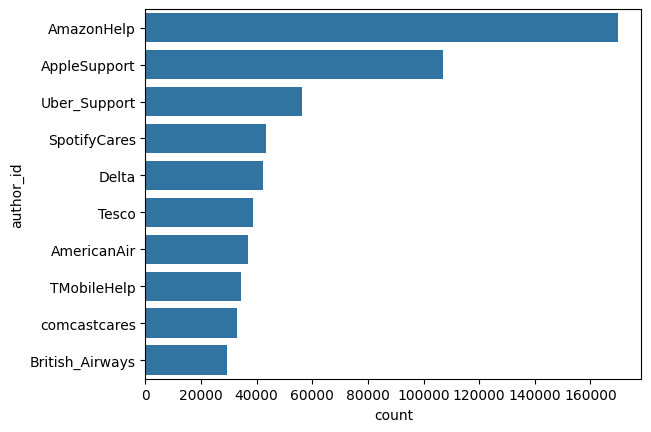

In [10]:
#filter only companies
companies = df[(df['inbound'] == False)]

#top 10 by count
order = companies['author_id'].value_counts().iloc[:10].index

#visualization
sns.countplot(companies['author_id'], order = order)

companies.head(5)

<function matplotlib.pyplot.show(close=None, block=None)>

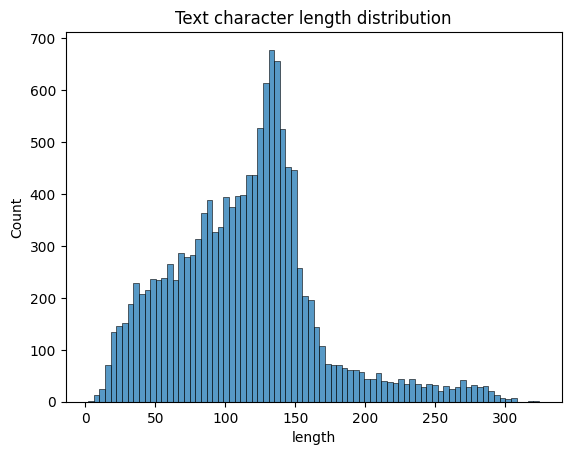

In [40]:
df_sample['chr_length'] = df_sample['text'].str.len()
sns.histplot(df_sample['chr_length'], bins = 80)

plt.title('Text character length distribution')
plt.xlabel('length')
plt.show

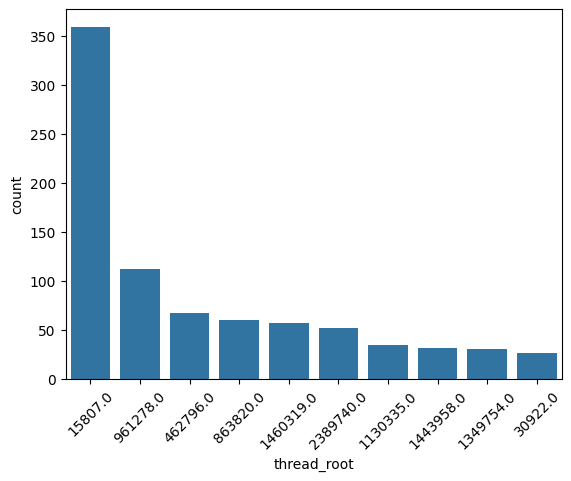

In [12]:
order1 = df_sample['thread_root'].value_counts().iloc[:10].index
sns.countplot(x = 'thread_root', data = df_sample, order = order1)
plt.xticks(rotation=45)
plt.show()

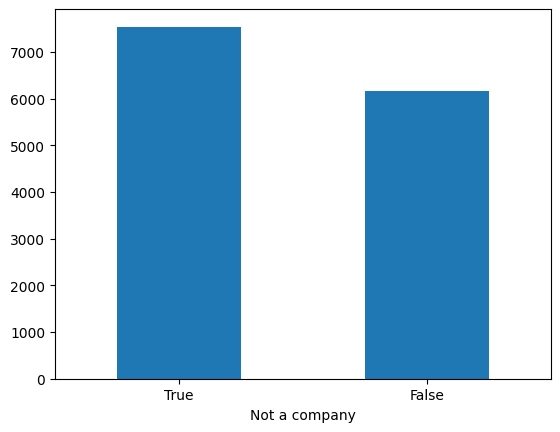

In [29]:
df_sample['inbound'].value_counts().plot(kind='bar')
plt.xlabel('Not a company')
plt.xticks(rotation = 0)
plt.show()

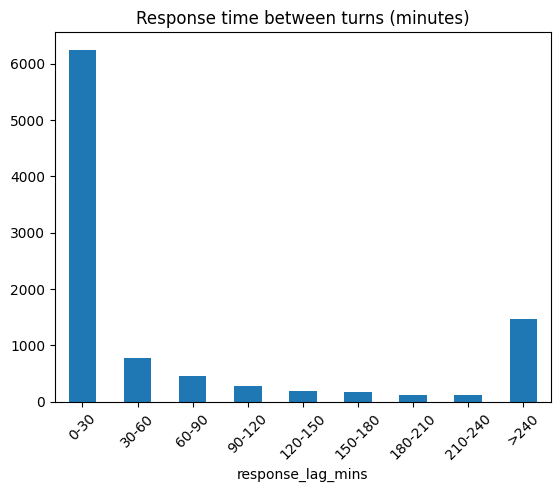

In [22]:
df_sample['response_lag_mins'] = df_sample.groupby('thread_root')['created_at'].diff().dt.total_seconds() / 60
lag = df_sample['response_lag_mins'].dropna()

bins = [0, 30, 60, 90, 120, 150, 180, 210, 240, np.inf]
labels = ['0-30', '30-60', '60-90', '90-120', '120-150', '150-180', '180-210', '210-240', '>240']

lag_binned = pd.cut(lag, bins=bins, labels=labels, right=False)
counts = lag_binned.value_counts().reindex(labels)
counts.plot(kind='bar')
plt.title('Response time between turns (minutes)')
plt.xticks(rotation=45)
plt.show()

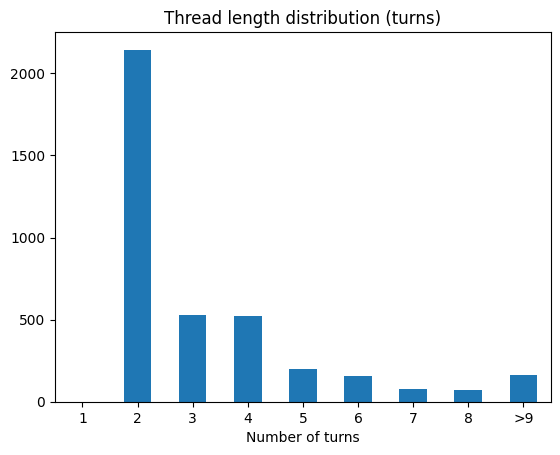

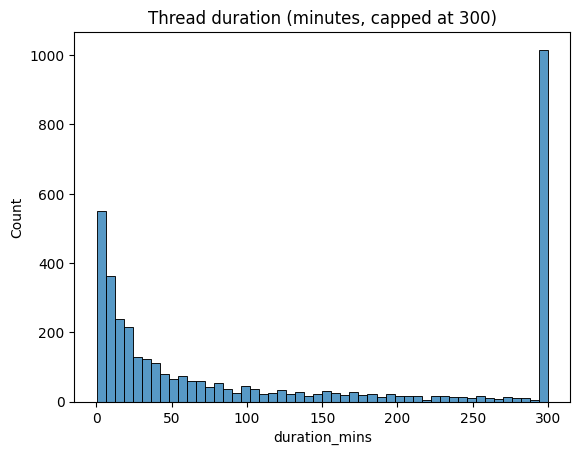

In [55]:
thread_stats = df_sample.groupby('thread_root').agg(
    turn_count=('tweet_id', 'count'),
    duration_mins=('created_at', lambda x: (x.max() - x.min()).total_seconds() / 60)
).reset_index()


bins1 = [1, 2, 3, 4, 5, 6, 7, 8, 9, np.inf]
labels1 = ['1', '2', '3', '4', '5', '6', '7', '8', '>9']
thr = thread_stats['turn_count']


thr_bin = pd.cut(thr, bins=bins1, labels=labels1, right=False)
counts = thr_bin.value_counts().reindex(labels)
counts.plot(kind='bar')

plt.title('Thread length distribution (turns)')
plt.xlabel('Number of turns')
plt.xticks(rotation = 0)
plt.show()

sns.histplot(thread_stats['duration_mins'].clip(upper=300), bins=50)
plt.title('Thread duration (minutes, capped at 300)')
plt.show()

In [35]:
pd.set_option('display.float_format', lambda x: '%.5f' % x)
print(thread_stats.describe())


        thread_root  turn_count  duration_mins
count    3859.00000  3859.00000     3859.00000
mean  1601513.82638     3.54859     2135.13671
std    849276.75546     6.75145    33302.98600
min       163.00000     2.00000        0.31667
25%    887927.50000     2.00000       13.42500
50%   1674472.00000     2.00000       58.85000
75%   2334625.50000     4.00000      341.81667
max   2987677.00000   359.00000  1679818.25000


In [67]:
thre = thread_stats[(thread_stats['duration_mins'] > 300)]
df_sample2 = df_sample[df_sample['thread_root'].isin(thre['thread_root'])]
df_sample2

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_terminal,turn_index,chr_length,response_lag_mins
2578,3505,116538,True,2017-10-31 22:23:48+00:00,i see you @77931 💁🏾✨✨✨ https://t.co/vxo3wtpwwt,"3504,3506",NaN,3505.00000,True,False,0,46,NaN
2577,3504,BofA_Help,False,2017-10-31 22:49:08+00:00,"@116538 hello, we saw your twitter post. is th...",NaN,3505.00000,3505.00000,False,True,1,83,25.33333
40671,3506,BofA_Help,False,2017-11-01 17:53:58+00:00,"@116538 hello, we are following up to see if y...",NaN,3505.00000,3505.00000,False,True,2,119,1144.83333
4454,5953,117132,True,2017-10-31 12:43:22+00:00,@airasiasupport how long do i need to wait for...,5952,NaN,5953.00000,True,False,0,134,NaN
4453,5952,AirAsiaSupport,False,2017-10-31 15:22:20+00:00,@117132 may we have the booking number you are...,5950,5953.00000,5953.00000,False,False,1,71,158.96667
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2810096,2986310,823437,True,2017-11-21 02:59:48+00:00,@hpsupport [type your question here] #hppsdr #...,2986309,NaN,2986310.00000,True,False,0,53,NaN
2810095,2986309,HPSupport,False,2017-11-21 12:45:03+00:00,"@823437 hi bobby, saw your tweet. are you expe...",NaN,2986310.00000,2986310.00000,False,True,1,245,585.25000
2810762,2986963,221257,True,2017-11-21 00:39:27+00:00,.@jetblue i’m disappointed i paid extra for #e...,2986962,NaN,2986963.00000,True,False,0,110,NaN
2810761,2986962,221257,True,2017-11-21 18:26:34+00:00,@jetblue disappointed in the lack of response ...,2986961,2986963.00000,2986963.00000,False,False,1,59,1067.11667


In [68]:
thre

,thread_root,turn_count,duration_mins
3,3505.00000,3,1170.16667
6,5953.00000,6,731.20000
8,7820.00000,4,1085.68333
11,8825.00000,2,2731.95000
16,15807.00000,359,18653.91667
...,...,...,...
3840,2976665.00000,2,3695.31667
3850,2984121.00000,2,2714.81667
3853,2986290.00000,2,3600.43333
3854,2986310.00000,2,585.25000


In [69]:
df_sample2.describe()

,tweet_id,in_response_to_tweet_id,thread_root,turn_index,chr_length,response_lag_mins
count,5156.00000,4146.00000,5156.00000,5156.00000,5156.00000,4146.00000
mean,1382800.97071,1284406.71032,1255046.83476,17.78530,115.35221,1947.32453
std,879227.22443,882269.74492,871990.83362,53.19709,52.60508,31892.53059
min,3504.00000,3505.00000,3505.00000,0.00000,5.00000,0.00000
25%,598250.00000,467991.00000,462796.00000,1.00000,79.00000,3.81667
50%,1349751.00000,1188738.50000,1130335.00000,2.00000,118.00000,44.88333
75%,2153846.25000,2030839.25000,1968796.00000,6.00000,142.00000,486.17500
max,2986963.00000,2986963.00000,2986963.00000,358.00000,324.00000,1679813.75000


In [70]:
df_sample.describe()

,tweet_id,in_response_to_tweet_id,thread_root,turn_index,chr_length,response_lag_mins
count,13694.00000,9835.00000,13694.00000,13694.00000,13694.00000,9835.00000
mean,1537257.75486,1478911.58200,1488425.77457,7.69519,113.69972,837.77250
std,866653.65179,877541.07988,874831.30882,33.61163,51.89807,20727.21174
min,160.00000,161.00000,163.00000,0.00000,2.00000,0.00000
25%,802259.50000,744800.00000,757890.00000,0.00000,78.00000,2.83333
50%,1552164.00000,1472323.00000,1493030.00000,1.00000,116.00000,12.26667
75%,2294522.75000,2249901.50000,2254365.25000,3.00000,140.00000,80.86667
max,2987677.00000,2987677.00000,2987677.00000,358.00000,324.00000,1679813.75000


In [75]:
df_sample['response_lag_mins'].value_counts()

response_lag_mins
0.03333       37
0.01667       35
0.00000       33
1.48333       27
0.05000       26
              ..
2714.81667     1
3600.43333     1
585.25000      1
1067.11667     1
29.98333       1
Name: count, Length: 4804, dtype: int64

In [74]:
df_sample

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_terminal,turn_index,chr_length,response_lag_mins
84,163,115737,True,2017-10-31 19:43:47+00:00,@chipotletweets can i dress up as myself and s...,162,NaN,163.00000,True,False,0,73,NaN
83,162,ChipotleTweets,False,2017-10-31 19:51:00+00:00,@115737 give it a try. -tara,161,163.00000,163.00000,False,False,1,28,7.21667
82,161,115737,True,2017-10-31 21:59:25+00:00,"@chipotletweets tried, didn't work. how rude :/",160,162.00000,163.00000,False,False,2,47,128.41667
81,160,ChipotleTweets,False,2017-10-31 22:06:55+00:00,@115737 my apologies for that. just sent you a...,NaN,161.00000,163.00000,False,True,3,65,7.50000
674,1214,115926,True,2017-10-31 22:20:26+00:00,celebrated halloween on a @southwestair flight...,1213,NaN,1214.00000,True,False,0,157,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2810760,2986961,JetBlue,False,2017-11-21 18:41:17+00:00,"@221257 sorry we missed your tweet, andrew. pl...",NaN,2986962.00000,2986963.00000,False,True,2,79,14.71667
2810939,2987139,548726,True,2017-11-21 20:21:07+00:00,@applesupport my iphone x crashed and now keep...,2987138,NaN,2987139.00000,True,False,0,123,NaN
2810938,2987138,AppleSupport,False,2017-11-21 20:41:28+00:00,@548726 hey there! thank you for reaching out ...,NaN,2987139.00000,2987139.00000,False,True,1,258,20.35000
2811498,2987677,823784,True,2017-11-22 03:43:22+00:00,なんか急にアマゾンから注文してた品物配達完了メールきて最近頼んだ覚えがないので？？？？てなっ...,2987676,NaN,2987677.00000,True,False,0,52,NaN


In [ ]:
with pd.option_context("display.max_rows", 1000):
    display(df_sample[df_sample['thread_root'] == 15807])

In [77]:
author_counts = (
    df.groupby('thread_root')['author_id']
    .nunique()
    .reset_index()
    .rename(columns={'author_id': 'n_distinct_authors'})
)

# Flag multi-party threads
author_counts['multi_party'] = author_counts['n_distinct_authors'] > 2

print(author_counts['n_distinct_authors'].value_counts().sort_index())
print(f"\nMulti-party threads: {author_counts['multi_party'].sum()}")

n_distinct_authors
1          86
2      740902
3       44499
4        6971
5        2103
        ...  
231         1
283         2
337         1
620         1
973         1
Name: count, Length: 120, dtype: int64

Multi-party threads: 57024
